# TelcoPeople — Pondération temporelle et apprentissage par récence

Le diagnostic précédent montre que juin 2023 est une période difficile, tandis que décembre 2023 et juin 2024 présentent un signal plus exploitable.

Ce notebook vérifie si le modèle gagne en pertinence lorsqu’il accorde davantage de poids aux observations récentes.

Les stratégies comparées sont :

1. **poids uniformes** : toutes les périodes historiques comptent de la même manière ;
2. **décroissance douce** : le poids diminue modérément avec l’ancienneté ;
3. **décroissance moyenne** ;
4. **décroissance forte** ;
5. **fenêtre glissante** : utilisation limitée aux périodes les plus récentes disponibles.

Le clustering et la détection d’anomalies sont reconstruits dans chaque fenêtre temporelle, sans utiliser la période de validation.

## 1. Bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 150)
sns.set_theme(style="whitegrid")

## 2. Chargement et préparation

In [2]:
CHEMIN = "../data/raw/"
train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")


def preparer_donnees(df):
    df = df.copy()

    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = df["departement"].fillna("INCONNU").str.strip().str.upper().str.replace("DEPT", "DEP", regex=False)
    df["contrat"] = df["contrat"].fillna("INCONNU").str.strip().str.upper().str.replace(".", "", regex=False)
    df["niveau_etude"] = df["niveau_etude"].fillna("INCONNU").str.strip().str.upper().str.replace(" ", "", regex=False).str.replace("BAC2", "BAC+2", regex=False)

    for col in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    for col in ["date_reference", "date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"]:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str).str.replace("FCFA", "", regex=False).str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (df["date_reference"] - df["date_derniere_promotion"]).dt.days / 365.25
    df["jours_depuis_absence"] = (df["date_reference"] - df["date_derniere_absence"]).dt.days

    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)

    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["performance_manquante"] = df["performance_actuelle"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

print("Train préparé :", train_prepare.shape)
print("Test préparé :", test_prepare.shape)

Train préparé : (5444, 64)
Test préparé : (1507, 63)


## 3. Fenêtres temporelles

In [3]:
PERIODES_VALIDATION = [
    pd.Timestamp("2023-06-30"),
    pd.Timestamp("2023-12-31"),
    pd.Timestamp("2024-06-30")
]

for periode in PERIODES_VALIDATION:
    print(
        periode.date(),
        "| train :", (train_prepare["date_reference"] < periode).sum(),
        "| validation :", (train_prepare["date_reference"] == periode).sum()
    )

2023-06-30 | train : 1858 | validation : 1083
2023-12-31 | train : 2941 | validation : 1189
2024-06-30 | train : 4130 | validation : 1314


## 4. Variables du clustering

In [4]:
VARIABLES_NUM_CLUSTER = [
    "age", "anciennete", "annees_depuis_promotion",
    "ratio_salaire_reference", "taux_evolution_salaire",
    "engagement_actuel", "engagement_precedent", "engagement_moyen",
    "performance_actuelle", "performance_precedente", "performance_moyenne",
    "jours_abs_6m", "nb_abs_6m", "abs_non_just_6m",
    "tendance_absence", "taille_departement"
]
VARIABLES_CAT_CLUSTER = ["contrat", "grade", "departement", "code_site"]
VARIABLES_CLUSTER = VARIABLES_NUM_CLUSTER + VARIABLES_CAT_CLUSTER

COLONNES_RETRAIT = [
    "target", "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]

## 5. Enrichissement non supervisé sans fuite temporelle

In [5]:
def enrichir_fold(train_fold, validation_fold, k=7):
    train_fold = train_fold.copy()
    validation_fold = validation_fold.copy()

    preprocesseur = ColumnTransformer([
        ("num", Pipeline([
            ("imputation", SimpleImputer(strategy="median")),
            ("standardisation", StandardScaler())
        ]), VARIABLES_NUM_CLUSTER),
        ("cat", Pipeline([
            ("imputation", SimpleImputer(strategy="most_frequent")),
            ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), VARIABLES_CAT_CLUSTER)
    ])

    Z_train = preprocesseur.fit_transform(train_fold[VARIABLES_CLUSTER])
    Z_validation = preprocesseur.transform(validation_fold[VARIABLES_CLUSTER])

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20).fit(Z_train)
    isolation = IsolationForest(
        n_estimators=400,
        contamination=0.03,
        random_state=42,
        n_jobs=-1
    ).fit(Z_train)

    def ajouter(df, matrice):
        distances = kmeans.transform(matrice)
        distances_triees = np.sort(distances, axis=1)
        df["cluster_rh"] = distances.argmin(axis=1).astype(str)
        df["distance_cluster"] = distances_triees[:, 0]
        df["marge_cluster"] = distances_triees[:, 1] - distances_triees[:, 0]
        df["score_anomalie"] = -isolation.score_samples(matrice)
        return df

    return ajouter(train_fold, Z_train), ajouter(validation_fold, Z_validation)

## 6. Stratégies de pondération temporelle

La demi-vie est exprimée en nombre de semestres. Par exemple, avec une demi-vie de 2, une observation datant de deux semestres reçoit environ la moitié du poids d’une observation de la période la plus récente.

In [6]:
STRATEGIES = {
    "Uniforme": {"demi_vie": None, "fenetre": None},
    "Décroissance douce": {"demi_vie": 4.0, "fenetre": None},
    "Décroissance moyenne": {"demi_vie": 2.0, "fenetre": None},
    "Décroissance forte": {"demi_vie": 1.0, "fenetre": None},
    "Fenêtre 2 périodes": {"demi_vie": None, "fenetre": 2},
    "Fenêtre 3 périodes": {"demi_vie": None, "fenetre": 3}
}

STRATEGIES

{'Uniforme': {'demi_vie': None, 'fenetre': None},
 'Décroissance douce': {'demi_vie': 4.0, 'fenetre': None},
 'Décroissance moyenne': {'demi_vie': 2.0, 'fenetre': None},
 'Décroissance forte': {'demi_vie': 1.0, 'fenetre': None},
 'Fenêtre 2 périodes': {'demi_vie': None, 'fenetre': 2},
 'Fenêtre 3 périodes': {'demi_vie': None, 'fenetre': 3}}

## 7. Calcul des poids de récence

In [7]:
def calculer_poids(dates, date_validation, demi_vie=None):
    ecart_mois = (
        (date_validation.year - dates.dt.year) * 12 +
        (date_validation.month - dates.dt.month)
    )
    ecart_semestres = ecart_mois / 6

    if demi_vie is None:
        return np.ones(len(dates))

    poids = np.power(0.5, ecart_semestres / demi_vie)
    return np.asarray(poids, dtype=float)

exemple = train_prepare.loc[
    train_prepare["date_reference"] < pd.Timestamp("2024-06-30"),
    ["date_reference"]
].copy()
exemple["poids_doux"] = calculer_poids(
    exemple["date_reference"], pd.Timestamp("2024-06-30"), demi_vie=4
)
exemple["poids_moyen"] = calculer_poids(
    exemple["date_reference"], pd.Timestamp("2024-06-30"), demi_vie=2
)
exemple["poids_fort"] = calculer_poids(
    exemple["date_reference"], pd.Timestamp("2024-06-30"), demi_vie=1
)

display(exemple.groupby("date_reference").mean())

,poids_doux,poids_moyen,poids_fort
date_reference,,,
2022-06-30,0.500000,0.250000,0.0625
2022-12-31,0.594604,0.353553,0.1250
2023-06-30,0.707107,0.500000,0.2500
2023-12-31,0.840896,0.707107,0.5000


## 8. Fonction d’entraînement pondéré

Les poids temporels sont combinés aux poids de classe. Cette combinaison évite que la récence annule la correction du déséquilibre entre départs et non-départs.

In [8]:
def entrainer_pondere(X_train, y_train, X_val, y_val, poids_temporels):
    n_negatifs = (y_train == 0).sum()
    n_positifs = (y_train == 1).sum()
    poids_positif = n_negatifs / max(n_positifs, 1)

    poids_classes = np.where(y_train.values == 1, poids_positif, 1.0)
    poids_finaux = poids_temporels * poids_classes
    poids_finaux = poids_finaux / poids_finaux.mean()

    cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=7,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False
    )

    modele.fit(
        X_train,
        y_train,
        sample_weight=poids_finaux,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150
    )

    return modele, modele.predict_proba(X_val)[:, 1]

## 9. Évaluation d’une stratégie sur les trois fenêtres

In [9]:
def evaluer_strategie(nom, parametres):
    predictions = []
    diagnostics = []

    for periode in PERIODES_VALIDATION:
        donnees_passees = train_prepare.loc[
            train_prepare["date_reference"] < periode
        ].copy()

        if parametres["fenetre"] is not None:
            periodes_disponibles = sorted(
                donnees_passees["date_reference"].unique()
            )
            periodes_retenues = periodes_disponibles[-parametres["fenetre"]:]
            train_fold = donnees_passees.loc[
                donnees_passees["date_reference"].isin(periodes_retenues)
            ].copy()
        else:
            train_fold = donnees_passees.copy()

        val_fold = train_prepare.loc[
            train_prepare["date_reference"] == periode
        ].copy()

        train_enrichi, val_enrichi = enrichir_fold(train_fold, val_fold)

        X_train = train_enrichi.drop(columns=COLONNES_RETRAIT)
        X_val = val_enrichi.drop(columns=COLONNES_RETRAIT)
        y_train = train_enrichi["target"]
        y_val = val_enrichi["target"]

        poids_temporels = calculer_poids(
            train_enrichi["date_reference"],
            periode,
            demi_vie=parametres["demi_vie"]
        )

        modele, proba = entrainer_pondere(
            X_train, y_train, X_val, y_val, poids_temporels
        )

        predictions.append(pd.DataFrame({
            "id": val_fold["id"].values,
            "periode": periode,
            "strategie": nom,
            "target": y_val.values,
            "probabilite": proba
        }))

        diagnostics.append({
            "strategie": nom,
            "periode": periode,
            "taille_train": len(train_fold),
            "nombre_periodes_train": train_fold["date_reference"].nunique(),
            "iteration": modele.get_best_iteration(),
            "auc": roc_auc_score(y_val, proba)
        })

    return pd.concat(predictions, ignore_index=True), pd.DataFrame(diagnostics)

## 10. Exécution des expériences

Cette cellule entraîne six stratégies sur trois fenêtres temporelles. Le calcul peut prendre plusieurs minutes.

In [10]:
predictions_toutes = []
diagnostics_tous = []

for nom, parametres in STRATEGIES.items():
    print("Évaluation :", nom)
    predictions_strategie, diagnostics_strategie = evaluer_strategie(
        nom, parametres
    )
    predictions_toutes.append(predictions_strategie)
    diagnostics_tous.append(diagnostics_strategie)

predictions_toutes = pd.concat(predictions_toutes, ignore_index=True)
diagnostics_tous = pd.concat(diagnostics_tous, ignore_index=True)

display(diagnostics_tous)

Évaluation : Uniforme
Évaluation : Décroissance douce
Évaluation : Décroissance moyenne
Évaluation : Décroissance forte
Évaluation : Fenêtre 2 périodes
Évaluation : Fenêtre 3 périodes


,strategie,periode,taille_train,nombre_periodes_train,iteration,auc
0,Uniforme,2023-06-30,1858,2,123,0.671337
1,Uniforme,2023-12-31,2941,3,338,0.716852
2,Uniforme,2024-06-30,4130,4,352,0.716894
3,Décroissance douce,2023-06-30,1858,2,93,0.680858
4,Décroissance douce,2023-12-31,2941,3,70,0.720426
5,Décroissance douce,2024-06-30,4130,4,220,0.718215
6,Décroissance moyenne,2023-06-30,1858,2,158,0.672235
7,Décroissance moyenne,2023-12-31,2941,3,250,0.718762
8,Décroissance moyenne,2024-06-30,4130,4,136,0.713388
9,Décroissance forte,2023-06-30,1858,2,136,0.674717


## 11. Sélection d’un seuil global par stratégie

Pour chaque stratégie, un seul seuil est choisi sur l’ensemble des prédictions hors temps.

In [11]:
resultats_seuils = []

for strategie, groupe in predictions_toutes.groupby("strategie"):
    for seuil in np.arange(0.20, 0.81, 0.01):
        pred = (groupe["probabilite"] >= seuil).astype(int)
        resultats_seuils.append({
            "strategie": strategie,
            "seuil": round(float(seuil), 2),
            "f1_global": f1_score(groupe["target"], pred),
            "precision_globale": precision_score(groupe["target"], pred, zero_division=0),
            "rappel_global": recall_score(groupe["target"], pred, zero_division=0)
        })

resultats_seuils = pd.DataFrame(resultats_seuils)
meilleurs_seuils = resultats_seuils.loc[
    resultats_seuils.groupby("strategie")["f1_global"].idxmax()
].sort_values("f1_global", ascending=False)

display(meilleurs_seuils)

,strategie,seuil,f1_global,precision_globale,rappel_global
39,Décroissance douce,0.59,0.299335,0.251397,0.369863
285,Fenêtre 3 périodes,0.57,0.298643,0.254335,0.361644
349,Uniforme,0.59,0.292683,0.263736,0.328767
161,Décroissance moyenne,0.57,0.290722,0.233058,0.386301
220,Fenêtre 2 périodes,0.54,0.289401,0.218056,0.430137
92,Décroissance forte,0.50,0.283654,0.200453,0.484932


## 12. Performance de chaque stratégie par période

In [12]:
resultats_par_periode = []

for _, choix in meilleurs_seuils.iterrows():
    strategie = choix["strategie"]
    seuil = choix["seuil"]
    donnees = predictions_toutes.loc[
        predictions_toutes["strategie"] == strategie
    ]

    for periode, groupe in donnees.groupby("periode"):
        pred = (groupe["probabilite"] >= seuil).astype(int)
        resultats_par_periode.append({
            "strategie": strategie,
            "periode": periode,
            "seuil_global": seuil,
            "f1": f1_score(groupe["target"], pred),
            "precision": precision_score(groupe["target"], pred, zero_division=0),
            "rappel": recall_score(groupe["target"], pred, zero_division=0),
            "auc": roc_auc_score(groupe["target"], groupe["probabilite"]),
            "positifs_predits": int(pred.sum())
        })

resultats_par_periode = pd.DataFrame(resultats_par_periode)
display(resultats_par_periode)

,strategie,periode,seuil_global,f1,precision,rappel,auc,positifs_predits
0,Décroissance douce,2023-06-30,0.59,0.250951,0.210191,0.311321,0.680858,157
1,Décroissance douce,2023-12-31,0.59,0.310954,0.287582,0.338462,0.720426,153
2,Décroissance douce,2024-06-30,0.59,0.325843,0.255507,0.449612,0.718215,227
3,Fenêtre 3 périodes,2023-06-30,0.57,0.237288,0.185185,0.330189,0.671337,189
4,Fenêtre 3 périodes,2023-12-31,0.57,0.333333,0.335938,0.330769,0.716852,128
5,Fenêtre 3 périodes,2024-06-30,0.57,0.326284,0.267327,0.418605,0.714205,202
6,Uniforme,2023-06-30,0.59,0.235741,0.197452,0.292453,0.671337,157
7,Uniforme,2023-12-31,0.59,0.333333,0.375000,0.300000,0.716852,104
8,Uniforme,2024-06-30,0.59,0.309598,0.257732,0.387597,0.716894,194
9,Décroissance moyenne,2023-06-30,0.57,0.240876,0.196429,0.311321,0.672235,168


## 13. Synthèse de robustesse

Le classement privilégie le F1 moyen. Le F1 minimum et l’écart-type servent à éviter une stratégie performante uniquement sur une période.

In [13]:
synthese = resultats_par_periode.groupby("strategie").agg(
    f1_moyen=("f1", "mean"),
    f1_minimum=("f1", "min"),
    f1_maximum=("f1", "max"),
    f1_ecart_type=("f1", "std"),
    auc_moyenne=("auc", "mean"),
    precision_moyenne=("precision", "mean"),
    rappel_moyen=("rappel", "mean")
)

synthese["score_robuste"] = (
    0.70 * synthese["f1_moyen"] +
    0.30 * synthese["f1_minimum"]
)

synthese = synthese.sort_values(
    ["score_robuste", "f1_moyen"], ascending=False
)

display(synthese)

,f1_moyen,f1_minimum,f1_maximum,f1_ecart_type,auc_moyenne,precision_moyenne,rappel_moyen,score_robuste
strategie,,,,,,,,
Décroissance douce,0.295916,0.250951,0.325843,0.039646,0.706500,0.251093,0.366465,0.282426
Fenêtre 3 périodes,0.298968,0.237288,0.333333,0.053533,0.700798,0.262816,0.359854,0.280464
Uniforme,0.292891,0.235741,0.333333,0.050896,0.701694,0.276728,0.326683,0.275746
Fenêtre 2 périodes,0.288563,0.240688,0.312500,0.041461,0.693698,0.218566,0.428040,0.274200
Décroissance moyenne,0.287961,0.240876,0.318339,0.041346,0.701462,0.236253,0.381929,0.273836
Décroissance forte,0.284497,0.243523,0.325967,0.041224,0.699653,0.204514,0.482543,0.272205


## 14. Visualisation des performances temporelles

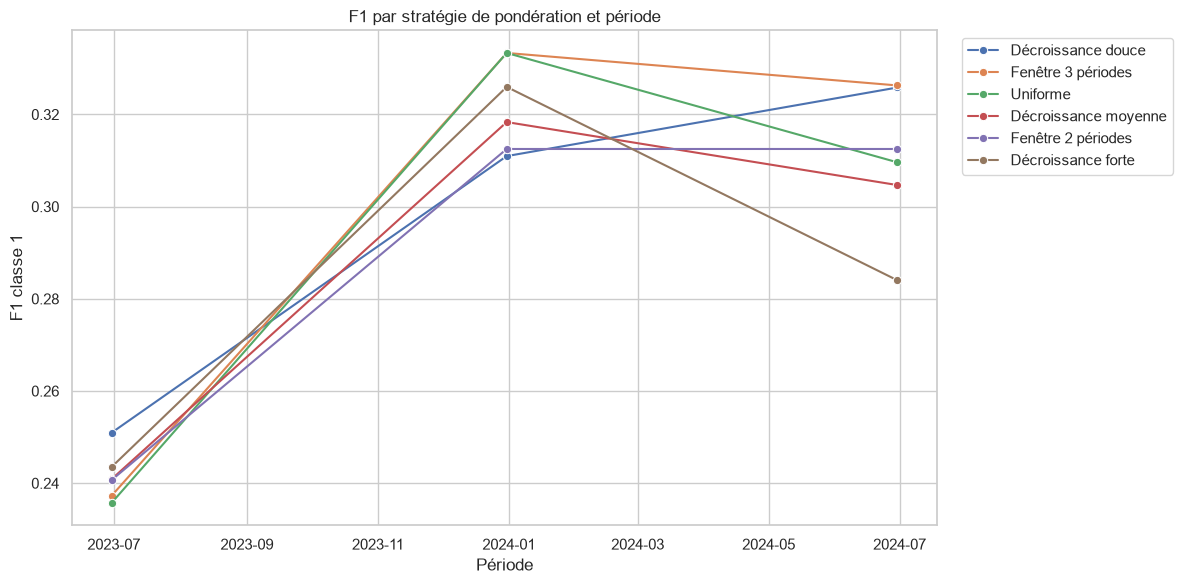

In [14]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=resultats_par_periode,
    x="periode",
    y="f1",
    hue="strategie",
    marker="o"
)
plt.title("F1 par stratégie de pondération et période")
plt.xlabel("Période")
plt.ylabel("F1 classe 1")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 15. Comparaison ciblée sur les périodes récentes

Le test final est daté de décembre 2024. Cette vue accorde donc une attention particulière à décembre 2023 et juin 2024, sans supprimer juin 2023 de l’évaluation globale.

In [15]:
periodes_recentes = [
    pd.Timestamp("2023-12-31"),
    pd.Timestamp("2024-06-30")
]

synthese_recente = resultats_par_periode.loc[
    resultats_par_periode["periode"].isin(periodes_recentes)
].groupby("strategie").agg(
    f1_recent_moyen=("f1", "mean"),
    f1_recent_minimum=("f1", "min"),
    auc_recente_moyenne=("auc", "mean"),
    precision_recente=("precision", "mean"),
    rappel_recent=("rappel", "mean")
).sort_values("f1_recent_moyen", ascending=False)

display(synthese_recente)

,f1_recent_moyen,f1_recent_minimum,auc_recente_moyenne,precision_recente,rappel_recent
strategie,,,,,
Fenêtre 3 périodes,0.329809,0.326284,0.715529,0.301632,0.374687
Uniforme,0.321465,0.309598,0.716873,0.316366,0.343798
Décroissance douce,0.318398,0.310954,0.719321,0.271544,0.394037
Fenêtre 2 périodes,0.312500,0.312500,0.704879,0.241429,0.443948
Décroissance moyenne,0.311504,0.304668,0.716075,0.256165,0.417233
Décroissance forte,0.304983,0.284000,0.712121,0.222843,0.502117


## 16. Décision automatique

La stratégie recommandée doit améliorer les périodes récentes tout en conservant un comportement raisonnable sur juin 2023.

In [16]:
meilleure_strategie = synthese.index[0]
meilleur_seuil = float(
    meilleurs_seuils.loc[
        meilleurs_seuils["strategie"] == meilleure_strategie,
        "seuil"
    ].iloc[0]
)

print("Stratégie la plus robuste :", meilleure_strategie)
print("Seuil global :", meilleur_seuil)
print("F1 moyen :", round(synthese.loc[meilleure_strategie, "f1_moyen"], 4))
print("F1 minimum :", round(synthese.loc[meilleure_strategie, "f1_minimum"], 4))
print("F1 récent moyen :", round(synthese_recente.loc[meilleure_strategie, "f1_recent_moyen"], 4))
print("AUC moyenne :", round(synthese.loc[meilleure_strategie, "auc_moyenne"], 4))

Stratégie la plus robuste : Décroissance douce
Seuil global : 0.59
F1 moyen : 0.2959
F1 minimum : 0.251
F1 récent moyen : 0.3184
AUC moyenne : 0.7065


## 17. Export des résultats

Aucune soumission n’est produite. Les paramètres retenus serviront au futur entraînement final.

In [17]:
predictions_toutes.to_csv(
    "../reports/predictions_pondération_temporelle.csv",
    index=False
)
diagnostics_tous.to_csv(
    "../reports/diagnostics_pondération_temporelle.csv",
    index=False
)
meilleurs_seuils.to_csv(
    "../reports/seuils_strategies_pondération.csv",
    index=False
)
resultats_par_periode.to_csv(
    "../reports/resultats_strategies_pondération.csv",
    index=False
)
synthese.to_csv("../reports/synthese_pondération_temporelle.csv")
synthese_recente.to_csv("../reports/synthese_periodes_recentes.csv")

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion

La pondération temporelle sera retenue seulement si elle apporte une amélioration reproductible sur les périodes récentes sans provoquer un effondrement supplémentaire sur juin 2023.

Si la stratégie uniforme reste meilleure, cela signifiera que les anciennes observations conservent de la valeur et que la faiblesse de juin 2023 ne doit pas être corrigée par une pondération générale.